## Milan Wouters — mijn bijdrage

**Eigen aandeel, bevestigd op 15 oktober 2026:** Meegewerkt aan de data cleaning en EDA van de Mushroom-data. Mijn oorspronkelijke cleaning-/EDA-uitwerking staat in [SolutionMilan](../../SolutionMilan/MushroomDataset/01_clean_en_explore.ipynb). Deze Final-leesversie gebruikt de 5.000 cursusrijen en behoudt Andrews bronvermelding; het oorspronkelijke onderzoek is gezamenlijk projectwerk.

**GenAI:** de code, structuur en documentatie zijn met hulp van OpenAI Codex uitgewerkt. Bij de recente review, Final-aanpassingen en technische eindcontrole was die hulp substantieel; ook de uitvoering van die controles gebeurde met Codex. Dit wordt niet als volledig zelfstandig geschreven code voorgesteld. Ik blijf verantwoordelijk voor het kunnen toelichten van mijn onderdeel.

Zie [bijdragen](../BIJDRAGEN.md), [GenAI Disclosure](../GENAI_DISCLOSURE.md) en de [uitgevoerde eindcontrole](../../solutions/milan/11_Final_eindcontrole.ipynb).

## Bijdragen en GenAI

**Brononderzoek:** Andrew Noeyens, volgens de bestaande bronvermelding. **Final-leesversie en aanvullende code/documentatie:** Codex op aanwijzing van Jorre. Dit schrijft Jorre niet automatisch het oorspronkelijke datasetonderzoek toe.

Jorres bevestigde projectbijdragen: pipeline, gezamenlijke backend, UI en AWS-training. Zie [bijdragen](../BIJDRAGEN.md) en [GenAI Disclosure](../GENAI_DISCLOSURE.md), inclusief vijf echte prompts en uitgevoerde controles. De individuele bijdragen en AI-inzet worden per teamlid vastgelegd; persoonlijke beheersing blijft een aparte controle.


# Mushroom — EDA op de 5.000 cursusrijen

Bronanalyse: Andrew Noeyens. Deze aparte leesversie is door Codex samengesteld op
verzoek van Jorre; Jorres bevestigde bijdrage staat in het centrale bijdragenoverzicht.
De bron blijft ongewijzigd in `MushroomFinal/mushroom_project.ipynb`.
De cellen hieronder onderzoeken de juiste cursus-CSV; modeltraining staat apart.
Het volledige bestand met 61.069 UCI-rijen hoort bij de historische experimenten.

We vinden de repository voordat we de bronanalyse uitvoeren.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'MushroomFinal/mushroom_project_dataset.csv').exists())
sys.path.insert(0, str(ROOT))


## 1 - EDA & Data Preparation

Before building a Machine Learning model, it is important to understand the structure and quality of the dataset. An Exploratory Data Analysis helps us identify patterns and understand the different values the data might provide for us.

In this section, the dataset is examined to understand its dimensions, column names, data types, and overall completeness. Based on these observations the data is prepared for modelling.

### Imported Libraries and Data Loading

The first step is to import the Python libraries required for data analysis and visualization. Pandas is used to load and examine the dataset. Seaborn and Matplotlib are used to create visualizations that help identify patterns, explore feature distributions.

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

The dataset is loaded from a CSV file into a Pandas DataFrame. To ensure consistent naming conventions and simplify future data manipulation, the column names are converted to lowercase, leading and trailing whitespace is removed, and hyphens are replaced with underscores.

The initial inspection reveals that the dataset contains a substantial number of missing values across several columns. Most of the features are also categorical, while only a small number contain numerical measurements.

In [3]:
mush = pd.read_csv(ROOT/'MushroomFinal/mushroom_project_dataset.csv')

mush.columns = mush.columns.str.strip().str.lower().str.replace('-', '_', regex=False)

mush.head()

,cap_diameter,stem_height,stem_width,spore_print_color,gill_color,habitat,season,ring_type,cap_shape,stem_surface,jumbled_noise_0,jumbled_noise_1,class
0,NaN,6.42,13.51,NaN,NaN,d,u,g,x,NaN,x,c,p
1,6.99,7.68,18.76,NaN,w,d,a,f,f,s,f,f,e
2,5.78,7.67,8.21,NaN,r,d,u,f,c,NaN,c,x,p
3,6.34,8.34,11.06,NaN,NaN,d,a,z,x,NaN,x,b,p
4,NaN,5.67,12.78,NaN,n,d,NaN,f,x,NaN,s,s,e


In [4]:
mush.info()

display(mush.nunique().rename('Amount of unique values').to_frame())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   cap_diameter       2968 non-null   float64
 1   stem_height        3987 non-null   float64
 2   stem_width         4605 non-null   float64
 3   spore_print_color  260 non-null    object 
 4   gill_color         4011 non-null   object 
 5   habitat            3996 non-null   object 
 6   season             4027 non-null   object 
 7   ring_type          4423 non-null   object 
 8   cap_shape          4594 non-null   object 
 9   stem_surface       1641 non-null   object 
 10  jumbled_noise_0    4594 non-null   object 
 11  jumbled_noise_1    4594 non-null   object 
 12  class              5000 non-null   object 
dtypes: float64(3), object(10)
memory usage: 507.9+ KB


,Amount of unique values
cap_diameter,1238
stem_height,1086
stem_width,2221
spore_print_color,7
gill_color,12
habitat,8
season,4
ring_type,8
cap_shape,7
stem_surface,8


### Understanding the features

To better understand the meaning of each variable, a feature dictionary is created based on the original dataset's documentation. It provides an overview of the features, their data types, and descriptions.

The dictionary distinguishes between metric features, which represent numerical measurements, and nominal features, which describe categorical characteristics of the mushrooms. It also identifies class as the binary target variable, where e represents edible mushrooms and p represents poisonous mushrooms or mushrooms of unknown edibility.

In [5]:
feature_info = {
    "cap-diameter": {
        "Type": "Metric",
        "Description": "Cap diameter in centimetres",
        "Category codes": "Continuous numeric value"
    },
    "cap-shape": {
        "Type": "Nominal",
        "Description": "Shape of the mushroom cap",
        "Category codes": "b: bell, c: conical, x: convex, f: flat, s: sunken, p: spherical, o: other"
    },
    "cap-surface": {
        "Type": "Nominal",
        "Description": "Surface texture of the cap",
        "Category codes": "i: fibrous, g: grooves, y: scaly, s: smooth, h: shiny, l: leathery, k: silky, t: sticky, w: wrinkled, e: fleshy"
    },
    "cap-color": {
        "Type": "Nominal",
        "Description": "Colour of the mushroom cap",
        "Category codes": "n: brown, b: buff, g: gray, r: green, p: pink, u: purple, e: red, w: white, y: yellow, l: blue, o: orange, k: black"
    },
    "does-bruise-bleed": {
        "Type": "Nominal",
        "Description": "Whether the mushroom bruises or bleeds",
        "Category codes": "t: yes, f: no"
    },
    "gill-attachment": {
        "Type": "Nominal",
        "Description": "How the gills attach to the stem",
        "Category codes": "a: adnate, x: adnexed, d: decurrent, e: free, s: sinuate, p: pores, f: none, ?: unknown"
    },
    "gill-spacing": {
        "Type": "Nominal",
        "Description": "Spacing between the gills",
        "Category codes": "c: close, d: distant, f: none"
    },
    "gill-color": {
        "Type": "Nominal",
        "Description": "Colour of the gills",
        "Category codes": "Same colour codes as cap-color; f: none"
    },
    "stem-height": {
        "Type": "Metric",
        "Description": "Stem height in centimetres",
        "Category codes": "Continuous numeric value"
    },
    "stem-width": {
        "Type": "Metric",
        "Description": "Stem width in millimetres",
        "Category codes": "Continuous numeric value"
    },
    "stem-root": {
        "Type": "Nominal",
        "Description": "Shape or structure of the stem root",
        "Category codes": "b: bulbous, s: swollen, c: club, u: cup, e: equal, z: rhizomorphs, r: rooted"
    },
    "stem-surface": {
        "Type": "Nominal",
        "Description": "Surface texture of the stem",
        "Category codes": "Same texture codes as cap-surface; f: none"
    },
    "stem-color": {
        "Type": "Nominal",
        "Description": "Colour of the stem",
        "Category codes": "Same colour codes as cap-color; f: none"
    },
    "veil-type": {
        "Type": "Nominal",
        "Description": "Type of veil",
        "Category codes": "p: partial, u: universal"
    },
    "veil-color": {
        "Type": "Nominal",
        "Description": "Colour of the veil",
        "Category codes": "Same colour codes as cap-color; f: none"
    },
    "has-ring": {
        "Type": "Nominal",
        "Description": "Whether a ring is present",
        "Category codes": "t: ring present, f: no ring"
    },
    "ring-type": {
        "Type": "Nominal",
        "Description": "Type of ring",
        "Category codes": "c: cobwebby, e: evanescent, r: flaring, g: grooved, l: large, p: pendant, s: sheathing, z: zone, y: scaly, m: movable, f: none, ?: unknown"
    },
    "spore-print-color": {
        "Type": "Nominal",
        "Description": "Colour of the spore print",
        "Category codes": "Same colour codes as cap-color"
    },
    "habitat": {
        "Type": "Nominal",
        "Description": "Habitat where the mushroom grows",
        "Category codes": "g: grasses, l: leaves, m: meadows, p: paths, h: heaths, u: urban, w: waste, d: woods"
    },
    "season": {
        "Type": "Nominal",
        "Description": "Season associated with the mushroom",
        "Category codes": "s: spring, u: summer, a: autumn, w: winter"
    },
    "class": {
        "Type": "Binary target",
        "Description": "Edibility label",
        "Category codes": "e: edible, p: poisonous or unknown edibility"
    }
}

feature_df = pd.DataFrame.from_dict(
    feature_info,
    orient="index"
)

feature_df.index.name = "Feature"

print("MUSHROOM DATASET — FEATURE DICTIONARY")
display(feature_df)


MUSHROOM DATASET — FEATURE DICTIONARY


,Type,Description,Category codes
Feature,,,
cap-diameter,Metric,Cap diameter in centimetres,Continuous numeric value
cap-shape,Nominal,Shape of the mushroom cap,"b: bell, c: conical, x: convex, f: flat, s: su..."
cap-surface,Nominal,Surface texture of the cap,"i: fibrous, g: grooves, y: scaly, s: smooth, h..."
cap-color,Nominal,Colour of the mushroom cap,"n: brown, b: buff, g: gray, r: green, p: pink,..."
does-bruise-bleed,Nominal,Whether the mushroom bruises or bleeds,"t: yes, f: no"
gill-attachment,Nominal,How the gills attach to the stem,"a: adnate, x: adnexed, d: decurrent, e: free, ..."
gill-spacing,Nominal,Spacing between the gills,"c: close, d: distant, f: none"
gill-color,Nominal,Colour of the gills,Same colour codes as cap-color; f: none
stem-height,Metric,Stem height in centimetres,Continuous numeric value


### Target

First we cover the target variable: class. When counting all records of each type, we discover there are 2 possible results, those being 'poisonous' and 'edible.'

By visualizing the distribution, it becomes clear about 2/3 of the results consist of edible mushrooms, meaning there is a relative imbalance in the dataset.

In [6]:
sns.set_theme(style="whitegrid", context="notebook")
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=mush,
    x='class',
    hue='class',
    order=['e', 'p'],
    palette={'e': 'green', 'p': 'red'},
    legend=False,
    width=0.5
)

for container in ax.containers:
    ax.bar_label(container, padding=4, fmt='%.0f')
    
ax.set_xticks([0, 1])
ax.set_xticklabels(['Edible', 'Poisonous'])

plt.title('Mushroom Class Distribution', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Mushroom Class', fontsize=12)
plt.ylabel('Number of Mushrooms', fontsize=12)

sns.despine()
plt.tight_layout()
plt.show()

<Figure size 800x500 with 1 Axes>

### Missing Values

Since the initial inspection revealed a substantial amount of missing data, this visualization examines the number of null values in each feature. This analysis is important because missing data can reduce the amount of information available to the model and may introduce bias if the missingness is not random.

Through this code we observe that 'spore print color', 'stem surface', and 'cap diameter' have the highest amount of missing values throughout the csv file. 

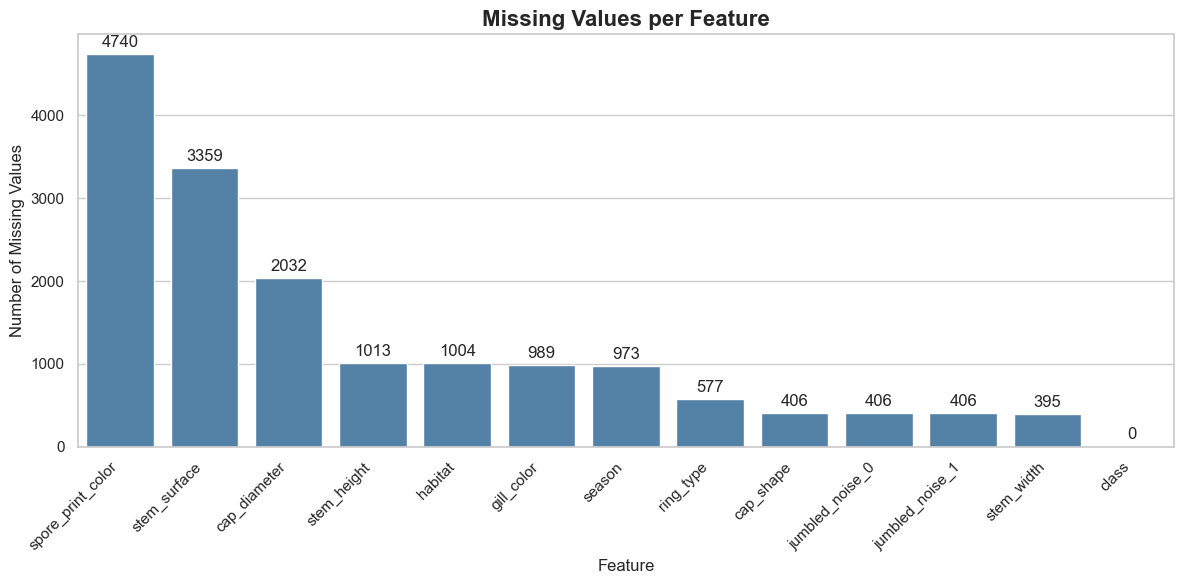

In [7]:
null_counts = mush.isnull().sum().sort_values(ascending=False)

null_df = null_counts.reset_index()
null_df.columns = ['Feature', 'Missing Values']

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=null_df,
    x='Feature',
    y='Missing Values',
    color='steelblue'
)

ax.bar_label(ax.containers[0], padding=3, fmt='%d')

plt.title('Missing Values per Feature', fontsize=16, fontweight='bold')
plt.xlabel('Feature')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Numerical features

The numerical features are examined to understand their distributions, ranges, and potential outliers. Histograms provide an overview of the frequency of different measurement values, while boxplots help identify extreme observations.

The histograms show that 'cap diameter', 'stem height', and 'stem width' are all more concentrated towards the lower values, with some small outliers around the higher measurements.

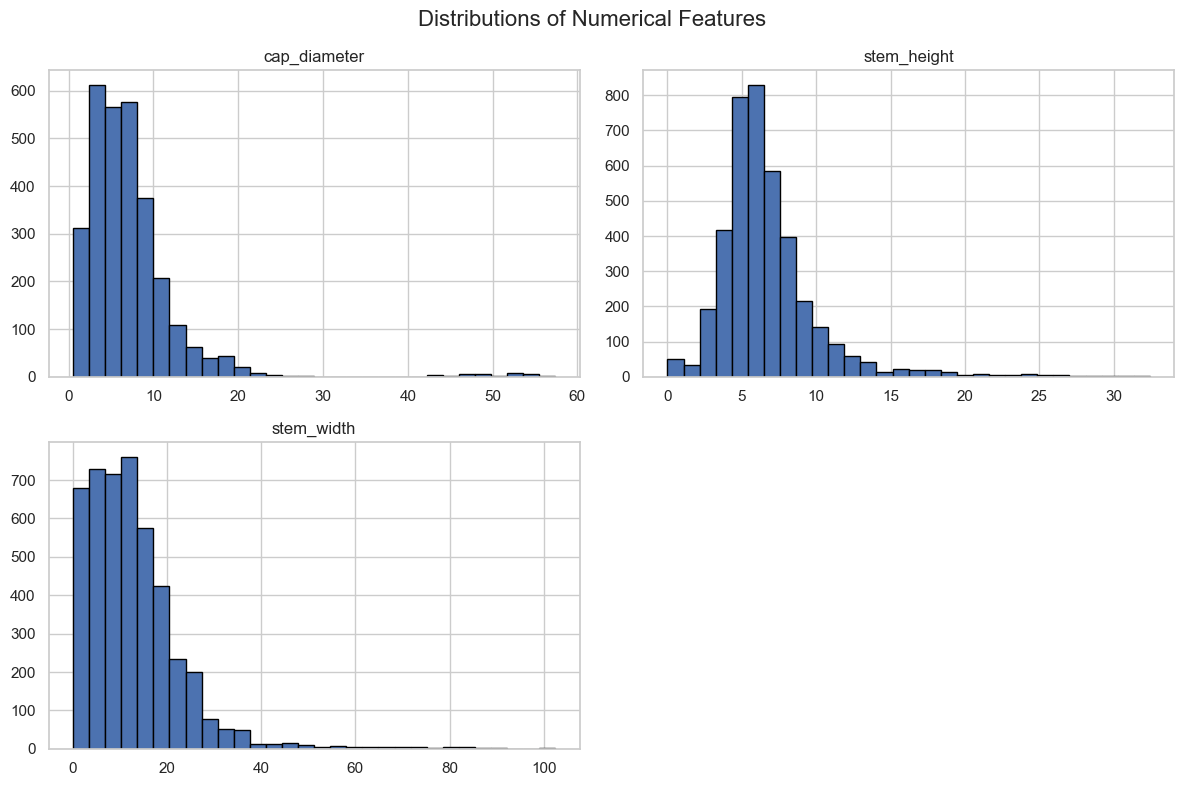

In [8]:
numerical_cols = mush.select_dtypes(include='number').columns.tolist()

if numerical_cols:
    mush[numerical_cols].hist(
        figsize=(12, 8),
        bins=30,
        edgecolor='black'
    )
    plt.suptitle('Distributions of Numerical Features', fontsize=16)
    plt.tight_layout()
    plt.show()

The boxplot comparisons show that edible mushrooms overall have a slightly higher median (with an exception for stem height) than the poisonous counterpart. While distribution is spread out a bit more, there still remains a decently large overlap, meaning that relying on the edible class alone will not be enough.

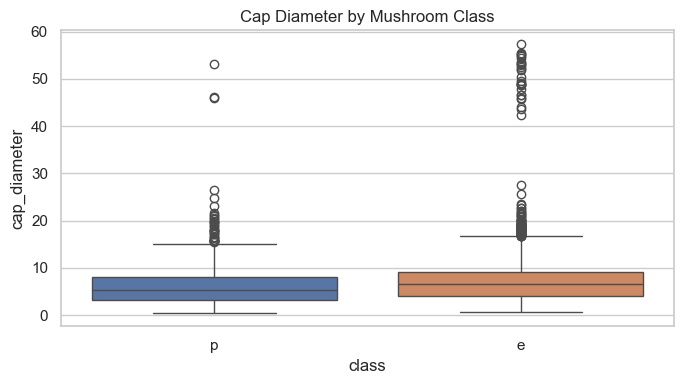

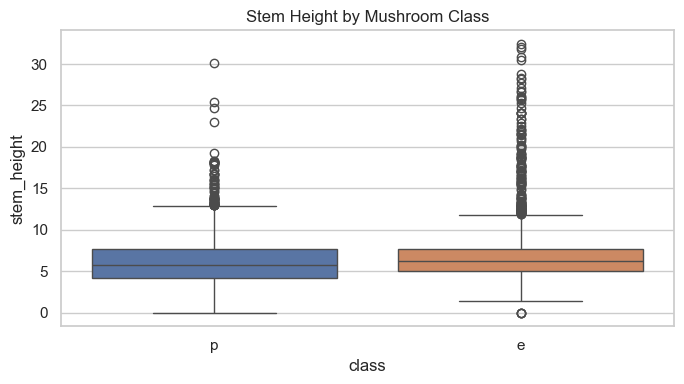

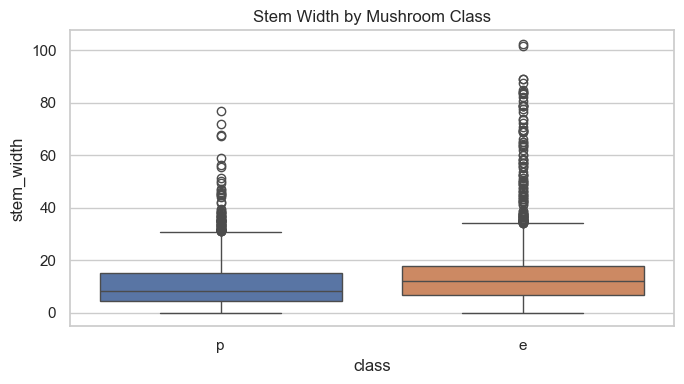

In [9]:
for col in numerical_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=mush, x='class', y=col, hue='class', legend=False)
    plt.title(f'{col.replace("_", " ").title()} by Mushroom Class')
    plt.tight_layout()
    plt.show()

### Noise features

In the assignment it was made clear several columns of static noise were added to increase the difficulty of the dataset. Such features may add complexity without improving predictive performance. Therefore it is important to know how we should evaluate these later on.

In [10]:
noise_cols = [col for col in mush.columns if 'jumbled_noise' in col]

for col in noise_cols:
    print(f'\n{col}')
    display(mush[col].value_counts(dropna=False).head(20).to_frame('Count'))
    display(pd.crosstab(mush[col], mush['class'], normalize='index').round(3))


jumbled_noise_0


,Count
jumbled_noise_0,
x,2060
f,1078
s,533
NaN,406
b,354
o,218
p,207
c,144


class,e,p
jumbled_noise_0,,
b,0.624,0.376
c,0.569,0.431
f,0.620,0.380
o,0.656,0.344
p,0.638,0.362
s,0.614,0.386
x,0.629,0.371



jumbled_noise_1


,Count
jumbled_noise_1,
x,2060
f,1078
s,533
NaN,406
b,354
o,218
p,207
c,144


class,e,p
jumbled_noise_1,,
b,0.613,0.387
c,0.521,0.479
f,0.647,0.353
o,0.550,0.450
p,0.623,0.377
s,0.589,0.411
x,0.634,0.366


### Conclusion

The EDA revealed that the dataset contains a large amount of missing data, predominantly in categorical features. Most of the dataset consists of this categorical data, with only a small amount of numerical info, which will require a form of encoding in the training process. We also found out there's a moderate imbalance in the target class that will have to be taken into account.

The next step is to ready the data for Machine Learning.